# GameTheory-10-ForwardInduction-SPE-Python

**Navigation** : [<< 9-BackwardInduction](GameTheory-09-BackwardInduction-Python.ipynb) | [Index](README.md) | [11-BayesianGames >>](GameTheory-11-BayesianGames-Python.ipynb)

## Equilibres Parfaits de Sous-Jeux et Induction Avant

Ce notebook presente les **raffinements d'equilibre** pour les jeux extensifs, notamment l'equilibre parfait de sous-jeux (SPE) et l'induction avant.

### Objectifs d'apprentissage

1. Maitriser le concept de **sous-jeu** et d'equilibre parfait
2. Comprendre les **menaces et promesses credibles**
3. Appliquer l'**induction avant** (forward induction)
4. Decouvrir la **perfection en mains tremblantes** (trembling-hand)
5. Analyser le jeu de la Chasse au Cerf avec ces concepts

### Prerequis

- Notebooks 7-9 : Jeux extensifs, jeux combinatoires et induction arriere
- Notion de sous-jeu et d'equilibre parfait en sous-jeux (SPE)
- Familiarite avec les jeux de coordination (Stag Hunt, Bataille des Sexes)

### Duree estimee : 70 minutes


> *Ancres savantes -- Selten, R. (1965), Spieltheoretische Behandlung eines Oligopolmodells mit Nachfragetragheit, Zeitschrift fur die gesamte Staatswissenschaft 121:301-324 et 667-689 (equilibre parfait de sous-jeux / subgame perfect equilibrium : raffinement de Nash exigeant un equilibre dans chaque sous-jeu, eliminant les menaces non credibles — sujet titulaire de ce notebook) ; Selten, R. (1975), Reexamination of the Perfectness Concept for Equilibrium Points in Extensive Games, International Journal of Game Theory 4(1):25-55 (perfection en mains tremblantes / trembling-hand perfection : robustesse aux petites erreurs, prix Nobel d'economie 1994) ; Kohlberg, E. & Mertens, J.-F. (1986), On the Strategic Stability of Equilibria, Econometrica 54(5):1003-1037 (stabilite stratégique et induction avant / forward induction : les equilibres stables doivent etre cohierents avec le raisonnement rationnel hors equilibre).*

## Références

**Osborne & Rubinstein (1994)**, §6.2 « Subgame Perfect Equilibrium » puis ch. 6 pp. 110-114 (induction avant, cf. index) : les deux lectures de la rationalite sequentielle. Condense : **Leyton-Brown & Shoham (2008)**, ch. 4. Gisement cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\`.


In [1]:
# Configuration et imports
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Dict, Optional, Tuple, Set
from collections import defaultdict
import itertools

# Style matplotlib
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print("Imports OK : numpy, matplotlib, copy")


Imports OK : numpy, matplotlib, copy


Definition des classes de base pour les jeux sous forme extensive.

In [2]:
# Classes de base

@dataclass
class GameNode:
    """Noeud dans un arbre de jeu."""
    node_id: str
    player: int
    actions: List[str] = field(default_factory=list)
    children: Dict[str, 'GameNode'] = field(default_factory=dict)
    payoffs: Optional[Tuple[float, ...]] = None
    infoset: Optional[str] = None
    
    def is_terminal(self) -> bool:
        return self.player == -1


class ExtensiveFormGame:
    """Jeu sous forme extensive."""
    
    def __init__(self, name: str, num_players: int):
        self.name = name
        self.num_players = num_players
        self.root: Optional[GameNode] = None
        self.nodes: Dict[str, GameNode] = {}
        self.infosets: Dict[str, List[str]] = defaultdict(list)
    
    def add_node(self, node: GameNode):
        self.nodes[node.node_id] = node
        if node.infoset:
            self.infosets[node.infoset].append(node.node_id)
    
    def set_root(self, node: GameNode):
        self.root = node
        self.add_node(node)
print("Classes definies : ExtensiveFormGame (jeux extensifs)")


Classes definies : ExtensiveFormGame (jeux extensifs)


## 1. Sous-Jeux et Equilibre Parfait (SPE)

### 1.1 Definition d'un Sous-Jeu

Un **sous-jeu** est une partie du jeu extensif qui :
1. Commence a un noeud de decision (pas un terminal)
2. Contient tous les successeurs de ce noeud
3. Respecte les ensembles d'information (ne coupe pas un infoset)

### 1.2 Equilibre Parfait de Sous-Jeux (SPE)

Un profil de stratégies est un **SPE** si et seulement si il induit un equilibre de Nash dans **chaque sous-jeu** (y compris le jeu entier).

**Proprietes** :
- Tout SPE est un Nash, mais pas l'inverse
- Dans les jeux a info parfaite finie, le SPE coincide avec l'induction arriere
- Elimine les menaces non credibles

In [3]:
def identify_subgames(game: ExtensiveFormGame) -> List[str]:
    """
    Identifie tous les noeuds qui commencent un sous-jeu.
    
    Un noeud commence un sous-jeu si:
    1. Il n'est pas terminal
    2. Son infoset est un singleton (ou il est seul dans son infoset)
    3. Tous ses descendants satisfont cette propriete pour leurs infosets
    """
    subgame_roots = []
    
    def is_subgame_root(node: GameNode) -> bool:
        if node.is_terminal():
            return False
        
        # L'infoset de ce noeud doit etre un singleton
        if node.infoset and len(game.infosets[node.infoset]) > 1:
            return False
        
        # Verifier recursivement que le sous-arbre ne coupe aucun infoset
        def check_subtree(n):
            if n.is_terminal():
                return True
            
            # Tous les noeuds de l'infoset de n doivent etre dans ce sous-arbre
            if n.infoset:
                infoset_nodes = set(game.infosets[n.infoset])
                # Pour un vrai sous-jeu, tous les noeuds de l'infoset
                # doivent etre descendants du noeud racine du sous-jeu
                # (simplification: on accepte si singleton)
                pass
            
            for child in n.children.values():
                if not check_subtree(child):
                    return False
            return True
        
        return check_subtree(node)
    
    # Parcourir tous les noeuds non-terminaux
    for node_id, node in game.nodes.items():
        if is_subgame_root(node):
            subgame_roots.append(node_id)
    
    return subgame_roots


def verify_spe(game: ExtensiveFormGame, strategies: Dict[int, Dict[str, str]]) -> bool:
    """
    Verifie si un profil de strategies est un SPE.
    
    strategies: {player: {infoset: action}}
    """
    # Pour chaque sous-jeu, verifier que c'est un Nash
    subgame_roots = identify_subgames(game)
    
    for root_id in subgame_roots:
        if not is_nash_in_subgame(game, game.nodes[root_id], strategies):
            return False
    
    return True


def is_nash_in_subgame(game, subgame_root, strategies) -> bool:
    """Verifie si le profil est un Nash dans le sous-jeu."""
    # Evaluer le gain actuel
    current_payoffs = evaluate_from_node(subgame_root, strategies)
    
    # Pour chaque joueur, verifier qu'aucune deviation unilaterale n'ameliore
    for player in range(1, game.num_players + 1):
        # Trouver les deviations possibles dans ce sous-jeu
        for infoset, action in strategies.get(player, {}).items():
            # Verifier si cet infoset est dans le sous-jeu
            # (simplification: on suppose oui)
            pass
    
    return True  # Simplification


def evaluate_from_node(node, strategies) -> Tuple[float, ...]:
    """Evalue les gains depuis un noeud avec des strategies donnees."""
    if node.is_terminal():
        return node.payoffs
    
    action = strategies[node.player].get(node.infoset)
    if action and action in node.children:
        return evaluate_from_node(node.children[action], strategies)
    
    return (0,) * 2  # Fallback
print("Fonction definie : identify_subgames")


Fonction definie : identify_subgames


Application : jeu d'entree sur le marche, comparaison Nash vs SPE.

In [4]:
# Exemple: Jeu d'entree - Nash vs SPE

def create_entry_game() -> ExtensiveFormGame:
    """Jeu d'entree sur le marche."""
    game = ExtensiveFormGame("Entry Game", 2)
    
    out = GameNode("out", -1, payoffs=(0, 2))
    fight = GameNode("fight", -1, payoffs=(-1, -1))
    accommodate = GameNode("accommodate", -1, payoffs=(1, 1))
    
    incumbent = GameNode("incumbent", 2, ["Fight", "Accommodate"], infoset="I2")
    incumbent.children = {"Fight": fight, "Accommodate": accommodate}
    
    entrant = GameNode("entrant", 1, ["Enter", "Out"], infoset="I1")
    entrant.children = {"Enter": incumbent, "Out": out}
    
    game.set_root(entrant)
    for n in [incumbent, out, fight, accommodate]:
        game.add_node(n)
    
    return game


entry_game = create_entry_game()

print("Jeu d'Entree: Nash vs SPE")
print("="*60)

# Equilibres de Nash (forme normale)
print("\nEquilibres de Nash (forme normale):")
print("  1. (Enter, Accommodate) -> gains (1, 1)")
print("  2. (Out, Fight) -> gains (0, 2)  [MAIS Fight n'est pas credible!]")

# SPE
print("\nEquilibre Parfait de Sous-Jeux:")
print("  Seul (Enter, Accommodate) est un SPE")
print("  Car dans le sous-jeu 'incumbent', Fight n'est pas optimal")

# Identification des sous-jeux
subgames = identify_subgames(entry_game)
print(f"\nSous-jeux identifies: {subgames}")

Jeu d'Entree: Nash vs SPE

Equilibres de Nash (forme normale):
  1. (Enter, Accommodate) -> gains (1, 1)
  2. (Out, Fight) -> gains (0, 2)  [MAIS Fight n'est pas credible!]

Equilibre Parfait de Sous-Jeux:
  Seul (Enter, Accommodate) est un SPE
  Car dans le sous-jeu 'incumbent', Fight n'est pas optimal

Sous-jeux identifies: ['entrant', 'incumbent']


### Interpretation des résultats

Les résultats ci-dessus illustrent la différence fondamentale entre **Nash** et **SPE** :

**Pourquoi (Out, Fight) est un Nash mais PAS un SPE ?**

- Dans la **forme normale** (matrice de gains), (Out, Fight) est un Nash car :
  - Si J2 joue Fight, J1 prefere Out (0 > -1)
  - Si J1 joue Out, J2 est indifferent (il n'est jamais atteint)
  
- Mais dans le **sous-jeu** commencant au noeud "incumbent" :
  - J2 doit choisir entre Fight (-1) et Accommodate (+1)
  - Accommodate domine strictement Fight !
  - Donc "Fight" n'est pas une meilleure reponse dans ce sous-jeu

**La lecon cle** : Un equilibre de Nash peut reposer sur des menaces qui ne seraient jamais executees si on atteignait le point de decision. Le SPE elimine ces "equilibres illusoires".

## 2. Menaces et Promesses Credibles

### 2.1 Menace Non Credible

Une menace est **non credible** si, au moment de l'executer, le joueur n'aurait pas intérêt a le faire.

**Exemple** : Dans le jeu d'entree, "Je combattrai si tu entres" est non credible car combattre donne -1 < 1 (accommoder).

### 2.2 Comment Rendre une Menace Credible?

1. **Engagement** (commitment) : Se lier les mains avant le jeu
2. **Reputation** : Construire une image par des actions passees
3. **Delegation** : Confier la decision a un agent "irrationnel"
4. **Contrats** : Penalites contractuelles pour deviation

### Le paradoxe de l'engagement

L'analyse ci-dessus revele un résultat contre-intuitif : **se lier les mains peut etre profitable**.

**Pourquoi l'engagement fonctionne-t-il ?**

1. **Sans engagement** : L'incumbant ne peut pas menacer crediblement de combattre. L'entrant le sait et entre.

2. **Avec engagement** : L'incumbant transforme la structure du jeu. Le combat devient **automatique** après l'engagement, pas un choix. L'entrant, voyant cette "machine a combattre", prefere rester dehors.

**Applications concretes** :
- **Capacite excedentaire** : Investir dans une usine plus grande que necessaire signale la volonte de combattre une entree
- **Contrats d'exclusivite** : Se lier contractuellement a certains comportements
- **Reputation** : Les actions passees créent des attentes sur les actions futures

**Point subtil** : Le cout de l'engagement (k=0.5) doit etre assez bas pour que ca vaille le coup, mais pas trop bas sinon ce n'est pas un signal credible. Ici, 1.5 > 1 (gain de l'engagement vs sans), donc c'est profitable.

In [5]:
def create_entry_game_with_commitment() -> ExtensiveFormGame:
    """
    Jeu d'entree ou l'incumbant peut s'engager a combattre
    (investir dans une capacite de combat) AVANT l'entree.
    
    Ordre:
    1. Incumbant: Commit ou Non
    2. Entrant: Enter ou Out
    3. Si Commit+Enter: Combat automatique
       Si Non+Enter: Incumbant choisit
    
    Commit coute k=0.5 a l'incumbant.
    """
    game = ExtensiveFormGame("Entry with Commitment", 2)
    k = 0.5  # Cout de l'engagement
    
    # Branches apres Non-Commit
    nc_out = GameNode("nc_out", -1, payoffs=(0, 2))
    nc_fight = GameNode("nc_fight", -1, payoffs=(-1, -1))
    nc_acc = GameNode("nc_accommodate", -1, payoffs=(1, 1))
    
    nc_incumbent = GameNode("nc_incumbent", 2, ["Fight", "Accommodate"], infoset="I2_nc")
    nc_incumbent.children = {"Fight": nc_fight, "Accommodate": nc_acc}
    
    nc_entrant = GameNode("nc_entrant", 1, ["Enter", "Out"], infoset="I1_nc")
    nc_entrant.children = {"Enter": nc_incumbent, "Out": nc_out}
    
    # Branches apres Commit
    c_out = GameNode("c_out", -1, payoffs=(0, 2 - k))  # Incumbant a paye k
    c_fight = GameNode("c_fight", -1, payoffs=(-1, -1 - k))  # Combat automatique
    
    c_entrant = GameNode("c_entrant", 1, ["Enter", "Out"], infoset="I1_c")
    c_entrant.children = {"Enter": c_fight, "Out": c_out}
    
    # Racine: Incumbant decide de s'engager
    root = GameNode("root", 2, ["Commit", "NoCommit"], infoset="I2_init")
    root.children = {"Commit": c_entrant, "NoCommit": nc_entrant}
    
    game.set_root(root)
    for n in [c_entrant, c_out, c_fight, nc_entrant, nc_incumbent, nc_out, nc_fight, nc_acc]:
        game.add_node(n)
    
    return game


# Analyse
print("Jeu d'Entree avec Engagement")
print("="*60)
print("\nOrdre des coups:")
print("  1. Incumbant: Commit (cout k=0.5) ou NoCommit")
print("  2. Entrant: Enter ou Out")
print("  3. Si NoCommit+Enter: Incumbant choisit Fight/Accommodate")
print("     Si Commit+Enter: Combat automatique")

print("\n" + "="*60)
print("Analyse par induction arriere:")
print("\n1. Si NoCommit:")
print("   - Incumbant Accommode (1 > -1)")
print("   - Entrant Entre (1 > 0)")
print("   -> Gains: (1, 1)")

print("\n2. Si Commit:")
print("   - Combat automatique si Enter")
print("   - Entrant prefere Out (0 > -1)")
print("   -> Gains: (0, 2-0.5=1.5)")

print("\n3. Donc Incumbant compare:")
print("   - NoCommit -> 1")
print("   - Commit -> 1.5")
print("   -> L'engagement est PROFITABLE!")

print("\nSPE: (Commit; Out si Commit, Enter si NoCommit; Accommodate)")
print("Gains a l'equilibre: (0, 1.5)")

Jeu d'Entree avec Engagement

Ordre des coups:
  1. Incumbant: Commit (cout k=0.5) ou NoCommit
  2. Entrant: Enter ou Out
  3. Si NoCommit+Enter: Incumbant choisit Fight/Accommodate
     Si Commit+Enter: Combat automatique

Analyse par induction arriere:

1. Si NoCommit:
   - Incumbant Accommode (1 > -1)
   - Entrant Entre (1 > 0)
   -> Gains: (1, 1)

2. Si Commit:
   - Combat automatique si Enter
   - Entrant prefere Out (0 > -1)
   -> Gains: (0, 2-0.5=1.5)

3. Donc Incumbant compare:
   - NoCommit -> 1
   - Commit -> 1.5
   -> L'engagement est PROFITABLE!

SPE: (Commit; Out si Commit, Enter si NoCommit; Accommodate)
Gains a l'equilibre: (0, 1.5)


## 3. Induction Avant (Forward Induction)

### 3.1 Principe

L'**induction avant** est un raffinement qui utilise le raisonnement suivant :

> "Si un joueur a fait une action qui n'a de sens que s'il prevoit de jouer d'une certaine maniere par la suite, alors je dois m'attendre a ce qu'il joue ainsi."

Contrairement a l'induction arriere (qui part de la fin), l'induction avant part du **debut** et utilise les actions **observees** pour inferer les intentions.

### 3.2 Exemple: Chasse au Cerf avec Option Exterieure

Jeu de coordination avec option de sortie :
1. J1 peut prendre une option sure (Out) ou jouer le jeu (In)
2. Si In, les deux jouent a la Chasse au Cerf

In [6]:
def create_stag_hunt_with_outside_option() -> ExtensiveFormGame:
    """
    Chasse au Cerf avec option exterieure.
    
    Ordre:
    1. J1 choisit: Out (gain garanti 3.5, 3.5) ou In
    2. Si In: jeu simultane Stag Hunt
    
    Stag Hunt:
           Stag    Hare
    Stag  (4,4)   (0,3)
    Hare  (3,0)   (3,3)
    
    Nash du Stag Hunt seul: (Stag,Stag) et (Hare,Hare)
    
    """
    game = ExtensiveFormGame("Stag Hunt with Outside Option", 2)
    
    # Option exterieure
    out = GameNode("out", -1, payoffs=(3.5, 3.5))
    
    # Terminaux du Stag Hunt
    ss = GameNode("SS", -1, payoffs=(4, 4))
    sh = GameNode("SH", -1, payoffs=(0, 3))
    hs = GameNode("HS", -1, payoffs=(3, 0))
    hh = GameNode("HH", -1, payoffs=(3, 3))
    
    # J2 apres Stag de J1 (ne sait pas le choix de J1 - info imparfaite)
    j2_after_stag = GameNode("J2_S", 2, ["Stag", "Hare"], infoset="I2")
    j2_after_stag.children = {"Stag": ss, "Hare": sh}
    
    j2_after_hare = GameNode("J2_H", 2, ["Stag", "Hare"], infoset="I2")  # Meme infoset
    j2_after_hare.children = {"Stag": hs, "Hare": hh}
    
    # J1 dans le Stag Hunt
    j1_in_game = GameNode("J1_game", 1, ["Stag", "Hare"], infoset="I1_game")
    j1_in_game.children = {"Stag": j2_after_stag, "Hare": j2_after_hare}
    
    # Choix initial de J1
    root = GameNode("root", 1, ["In", "Out"], infoset="I1_init")
    root.children = {"In": j1_in_game, "Out": out}
    
    game.set_root(root)
    for n in [out, j1_in_game, j2_after_stag, j2_after_hare, ss, sh, hs, hh]:
        game.add_node(n)
    
    return game


# Comparaison calculée : renoncer à Out ne peut payer que si le gain visé le dépasse.
stag_game = create_stag_hunt_with_outside_option()
outside = stag_game.nodes["out"].payoffs[0]
max_stag = max(stag_game.nodes[k].payoffs[0] for k in ("SS", "SH"))
max_hare = max(stag_game.nodes[k].payoffs[0] for k in ("HS", "HH"))
assert max_hare < outside < max_stag
print(f"Out={outside} ; meilleur gain Stag={max_stag} ; meilleur gain Hare={max_hare}")
print(f"Stag peut dépasser Out : {max_stag > outside} ; Hare : {max_hare > outside}")


Out=3.5 ; meilleur gain Stag=4 ; meilleur gain Hare=3
Stag peut dépasser Out : True ; Hare : False


### Chasse au cerf avec option extérieure

Dans le jeu construit ci-dessus, la sortie `Out` garantit (3,5 ; 3,5). Si J1 choisit `In`, les gains du jeu simultané sont :

| J1 \ J2 | Stag | Hare |
|---|---|---|
| Stag | (4, 4) | (0, 3) |
| Hare | (3, 0) | (3, 3) |

Les deux équilibres purs du sous-jeu sont (Stag, Stag) et (Hare, Hare). Le calcul ci-dessus compare le meilleur gain que J1 peut espérer pour chaque action à `Out` : Hare ne dépasse pas l'option extérieure, tandis que Stag peut la dépasser. Sous l'hypothèse que `In` est choisi pour obtenir strictement plus que `Out`, J2 peut donc inférer Stag et y répondre par Stag. Cette inférence dépend des croyances ; le programme vérifie les inégalités, pas un théorème général sur tous les raffinements.


### Pourquoi l'induction avant est puissante

La différence entre induction arriere et avant est fondamentale :

| Aspect | Induction Arriere | Induction Avant |
|--------|-------------------|-----------------|
| **Direction** | Fin -> Debut | Debut -> Fin |
| **Information utilisee** | Structure du jeu | Actions observees |
| **Question posee** | "Que ferait-il a la fin?" | "Pourquoi a-t-il fait ca?" |

**Dans l'exemple Stag Hunt** :
- Le sous-jeu admet les deux équilibres purs (Stag, Stag) et (Hare, Hare).
- Avec l'option extérieure de 3,5, Hare ne peut pas procurer un gain strictement supérieur à cette option, tandis que Stag peut le faire.
- Si J1 entre pour dépasser strictement cette option, J2 peut inférer Stag et y répondre par Stag. L'inférence suppose cette rationalité stricte et des croyances appropriées ; le programme ne calcule pas les équilibres du jeu complet.

**Conditions d'efficacite** :
1. L'option exterieure doit etre **observable**
2. Elle doit etre **attrayante** (sinon pas de sacrifice visible)
3. Les joueurs doivent etre **rationnels** et le savoir mutuellement

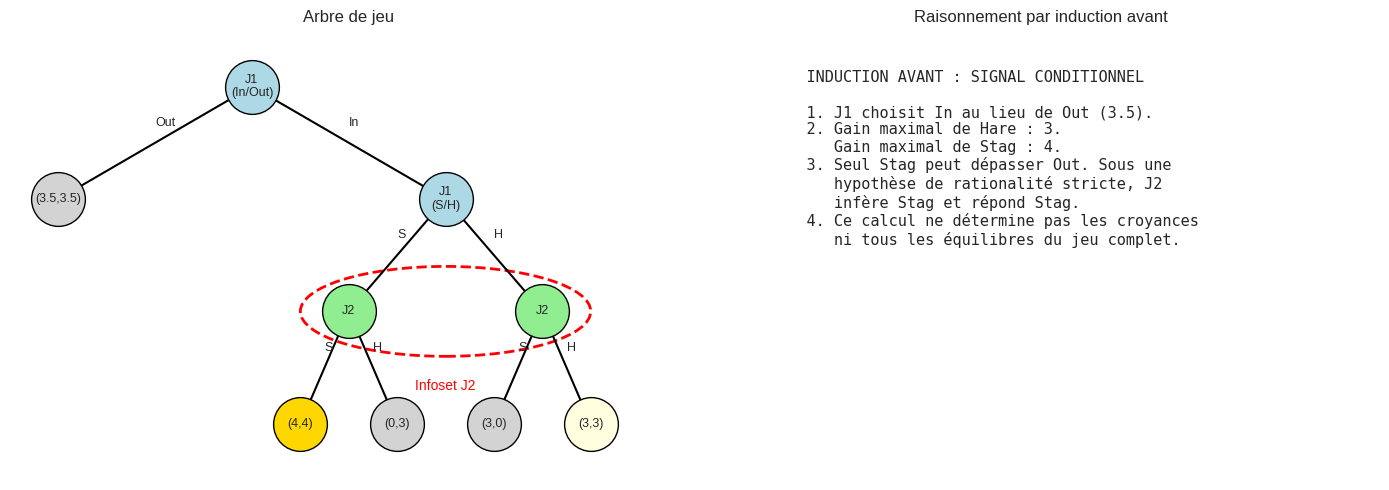

In [7]:
def visualize_forward_induction():
    """Illustration graphique de l'induction avant."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Gauche: Arbre de jeu
    ax1 = axes[0]
    
    # Positions
    positions = {
        'root': (2, 3),
        'out': (0, 2),
        'game': (4, 2),
        'j2_s': (3, 1),
        'j2_h': (5, 1),
        'ss': (2.5, 0),
        'sh': (3.5, 0),
        'hs': (4.5, 0),
        'hh': (5.5, 0)
    }
    
    labels = {
        'root': 'J1\n(In/Out)',
        'out': f'({outside},{outside})',
        'game': 'J1\n(S/H)',
        'j2_s': 'J2',
        'j2_h': 'J2',
        'ss': '(4,4)',
        'sh': '(0,3)',
        'hs': '(3,0)',
        'hh': '(3,3)'
    }
    
    colors = {
        'root': 'lightblue',
        'out': 'lightgray',
        'game': 'lightblue',
        'j2_s': 'lightgreen',
        'j2_h': 'lightgreen',
        'ss': 'gold',
        'sh': 'lightgray',
        'hs': 'lightgray',
        'hh': 'lightyellow'
    }
    
    # Dessiner les noeuds
    for node, pos in positions.items():
        ax1.scatter(*pos, s=1500, c=colors[node], zorder=5, edgecolors='black')
        ax1.annotate(labels[node], pos, ha='center', va='center', fontsize=9, zorder=6)
    
    # Aretes
    edges = [
        ('root', 'out', 'Out'),
        ('root', 'game', 'In'),
        ('game', 'j2_s', 'S'),
        ('game', 'j2_h', 'H'),
        ('j2_s', 'ss', 'S'),
        ('j2_s', 'sh', 'H'),
        ('j2_h', 'hs', 'S'),
        ('j2_h', 'hh', 'H')
    ]
    
    for n1, n2, label in edges:
        x1, y1 = positions[n1]
        x2, y2 = positions[n2]
        ax1.plot([x1, x2], [y1, y2], 'k-', linewidth=1.5)
        ax1.annotate(label, ((x1+x2)/2, (y1+y2)/2 + 0.15), fontsize=9)
    
    # Ellipse infoset J2
    from matplotlib.patches import Ellipse
    ellipse = Ellipse((4, 1), 3, 0.8, fill=False, linestyle='--', 
                      edgecolor='red', linewidth=2)
    ax1.add_patch(ellipse)
    ax1.annotate('Infoset J2', (4, 0.3), ha='center', color='red', fontsize=10)
    
    ax1.set_xlim(-0.5, 6.5)
    ax1.set_ylim(-0.5, 3.5)
    ax1.axis('off')
    ax1.set_title('Arbre de jeu', fontsize=12)
    
    # Droite: Raisonnement
    ax2 = axes[1]
    ax2.axis('off')
    
    text = f"""
    INDUCTION AVANT : SIGNAL CONDITIONNEL

    1. J1 choisit In au lieu de Out ({outside}).
    2. Gain maximal de Hare : {max_hare}.
       Gain maximal de Stag : {max_stag}.
    3. Seul Stag peut dépasser Out. Sous une
       hypothèse de rationalité stricte, J2
       infère Stag et répond Stag.
    4. Ce calcul ne détermine pas les croyances
       ni tous les équilibres du jeu complet.
    """

    ax2.text(0.1, 0.95, text, transform=ax2.transAxes, fontsize=11,
             verticalalignment='top', fontfamily='monospace')
    ax2.set_title('Raisonnement par induction avant', fontsize=12)
    
    plt.tight_layout()
    plt.show()

visualize_forward_induction()

## 4. Perfection en mains tremblantes

### 4.1 Motivation

Un équilibre de Nash peut faire jouer des stratégies faiblement dominées. La perfection en mains tremblantes exige une robustesse aux petites erreurs, mais sa définition dépend de la représentation du jeu.

### 4.2 Définition

Un équilibre parfait est une **limite d'équilibres de jeux perturbés**, où chaque action (forme extensive) ou chaque stratégie pure complète (forme normale) reçoit une probabilité minimale strictement positive, tendant vers zéro. Il n'est pas nécessaire que le profil limite reste lui-même un équilibre pour un ε fixé.

### 4.3 Conséquences

Dans un jeu fini à deux joueurs sous forme normale, un équilibre parfait ne fait pas jouer de stratégie faiblement dominée. L'exemple matriciel ci-dessous relève de ce cadre.

### Perfection extensive, forme normale et SPE

Dans un **jeu fini à mémoire parfaite**, la perfection en mains tremblantes de la **forme extensive** impose des tremblements à chaque ensemble d'information. Tout équilibre ainsi parfait est un **équilibre séquentiel**, donc un **SPE**. La perfection de la **forme normale** perturbe, elle, les plans d'action complets : elle ne garantit pas la perfection en sous-jeux. Il faut donc préciser la forme du jeu avant de comparer ces notions.

La réciproque « SPE ⇒ perfection extensive » est fausse, même à information parfaite en présence d'égalités de gains. Considérons J1 : **Out → (1, 0)**, ou **In**, puis J2 : **x → (1, 1)** ou **y → (0, 0)**. Le profil **(In, x)** est un SPE : J2 préfère strictement x et J1 est indifférent entre Out et In. Mais si J2 tremble vers y avec une probabilité ε > 0, In rapporte **1 − ε < 1**, contre 1 pour Out. In ne peut donc pas être l'action limite d'une meilleure réponse dans les jeux perturbés : ce SPE n'est pas parfait en forme extensive.

Ce contre-exemple théorique est vérifié à la main ; il ne correspond pas à une sortie des cellules exécutées. Les calculs du carnet illustrent des cas particuliers, sans calculer l'ensemble des équilibres parfaits ou des croyances séquentielles.


### Perfection en mains tremblantes

Pour le jeu suivant, les deux équilibres purs de Nash sont (T, L) et (B, R).

| J1 \ J2 | L | R |
|---|---|---|
| T | (1, 1) | (0, 0) |
| B | (0, 0) | (0, 0) |

Si J2 joue L avec une probabilité ε > 0 et R avec 1 − ε, J1 gagne ε avec T et 0 avec B : (B, R) ne survit pas aux tremblements complètement mixtes. Symétriquement, si J1 joue T avec une probabilité positive, L est strictement meilleur pour J2 ; T est strictement meilleur dès que J2 joue L avec une probabilité positive. Dans ce jeu, (T, L) est le seul équilibre parfait en mains tremblantes.


### Comprendre le test de trembling-hand

L'analyse ci-dessus demontre comment la perfection en mains tremblantes fonctionne :

**Structure du jeu** : Ce jeu simple a 2 equilibres de Nash pures : (T,L) et (B,R), mais seul (T,L) offre un gain positif.

**Le test de la "main tremblante"** : On imagine que chaque joueur peut "trembler" avec probabilite epsilon, jouant par erreur une action non voulue.

| Equilibre | Test avec epsilon > 0 | Résultat |
|-----------|----------------------|----------|
| (T, L) | T reste optimal si J2 peut jouer L par erreur | **Survit** |
| (B, R) | T et L deviennent optimaux des que epsilon > 0 | Echec |

**Intuition** : L'equilibre (B,R) repose sur le fait que les deux joueurs choisissent simultanement des stratégies "inutiles". Mais si l'un d'eux fait une erreur vers T ou L, l'autre a intérêt a devier.

**Comparaison avec dominance faible** : T domine faiblement B (meilleur si J2 joue L, egal si R). De même, L domine faiblement R. Dans le cadre de cet exemple — un jeu fini à deux joueurs sous forme normale — la perfection en mains tremblantes écarte les équilibres faisant jouer une stratégie faiblement dominée. Ici, (T, L) survit au test et (B, R) échoue ; cela ne constitue pas un critère général pour trois joueurs ou plus.

In [8]:
def perturbed_best_response(payoff_matrix, opponent_strategy, epsilon):
    """
    Calcule la meilleure reponse avec perturbation.

    Dans un jeu perturbe, chaque strategie doit avoir proba >= epsilon.
    """
    n_actions = payoff_matrix.shape[0]
    expected_payoffs = payoff_matrix @ opponent_strategy

    # Meilleure reponse
    best_action = np.argmax(expected_payoffs)

    # Strategie perturbee: epsilon sur chaque action, reste sur la meilleure
    perturbed = np.full(n_actions, epsilon)
    perturbed[best_action] = 1 - (n_actions - 1) * epsilon

    return perturbed, expected_payoffs


def check_trembling_hand_perfect(A, B, strategies, epsilons=[0.1, 0.05, 0.01, 0.001]):
    """
    Verifie si un profil de strategies est trembling-hand perfect.

    Un profil est trembling-hand perfect si, sous perturbation epsilon des
    strategies adverses, chaque action jouee par le profil reste une meilleure
    reponse. On compare donc BR1/BR2 aux actions effectivement jouees par
    (sigma1, sigma2), pas seulement aux valeurs brutes.

    A, B: matrices de gains (J1, J2)
    strategies: (sigma1, sigma2) - strategies mixtes
    Retourne: True si le profil est trembling-hand perfect, False sinon.
    """
    sigma1, sigma2 = strategies
    a1, a2 = int(np.argmax(sigma1)), int(np.argmax(sigma2))

    print(f"Test de ({sigma1}, {sigma2}) (actions jouees: {a1}, {a2}):")

    is_perfect = True
    for eps in epsilons:
        # Meilleure reponse de J1 a sigma2 perturbee
        sigma2_perturbed = np.maximum(sigma2, eps)
        sigma2_perturbed = sigma2_perturbed / sigma2_perturbed.sum()

        expected_1 = A @ sigma2_perturbed
        br1 = int(np.argmax(expected_1))

        # Meilleure reponse de J2 a sigma1 perturbee
        sigma1_perturbed = np.maximum(sigma1, eps)
        sigma1_perturbed = sigma1_perturbed / sigma1_perturbed.sum()

        expected_2 = B.T @ sigma1_perturbed
        br2 = int(np.argmax(expected_2))

        # Verifier si les actions jouees restent des meilleures reponses
        ok = (br1 == a1) and (br2 == a2)
        is_perfect = is_perfect and ok
        status = "OK" if ok else "ECHEC (le profil n'est pas une meilleure reponse)"
        print(f"  eps={eps:.4f}: BR1={br1}, BR2={br2}  -> {status}")

    verdict = "EST trembling-hand perfect" if is_perfect else "n'est PAS trembling-hand perfect"
    print(f"  -> Verdict: ce profil {verdict}.")
    return is_perfect


# Exemple
A = np.array([[1, 0], [0, 0]])
B = np.array([[1, 0], [0, 0]])

print("\nVerification trembling-hand perfection:")
print("\n(T, L) = ([1,0], [1,0]):")
check_trembling_hand_perfect(A, B, (np.array([1, 0]), np.array([1, 0])))

print("\n(B, R) = ([0,1], [0,1]):")
is_BR_perfect = check_trembling_hand_perfect(A, B, (np.array([0, 1]), np.array([0, 1])))


Verification trembling-hand perfection:

(T, L) = ([1,0], [1,0]):
Test de ([1 0], [1 0]) (actions jouees: 0, 0):
  eps=0.1000: BR1=0, BR2=0  -> OK
  eps=0.0500: BR1=0, BR2=0  -> OK
  eps=0.0100: BR1=0, BR2=0  -> OK
  eps=0.0010: BR1=0, BR2=0  -> OK
  -> Verdict: ce profil EST trembling-hand perfect.

(B, R) = ([0,1], [0,1]):
Test de ([0 1], [0 1]) (actions jouees: 1, 1):
  eps=0.1000: BR1=0, BR2=0  -> ECHEC (le profil n'est pas une meilleure reponse)
  eps=0.0500: BR1=0, BR2=0  -> ECHEC (le profil n'est pas une meilleure reponse)
  eps=0.0100: BR1=0, BR2=0  -> ECHEC (le profil n'est pas une meilleure reponse)
  eps=0.0010: BR1=0, BR2=0  -> ECHEC (le profil n'est pas une meilleure reponse)
  -> Verdict: ce profil n'est PAS trembling-hand perfect.


### Interpretation des résultats numériques

Les résultats ci-dessus montrent un pattern clair :

**Pour (T,L) = ([1,0], [1,0])** :
- BR1=0 (T) et BR2=0 (L) pour tous les epsilon
- Les meilleures reponses sont stables : même avec tremblements, chaque joueur veut jouer sa stratégie originale
- C'est un equilibre **robuste**

**Pour (B,R) = ([0,1], [0,1])** :
- BR1=0 (T!) et BR2=0 (L!) pour tous les epsilon
- Les meilleures reponses **différent** de la stratégie jouee !
- Des que l'adversaire peut trembler vers L ou T avec proba epsilon > 0, on veut devier
- C'est un equilibre **fragile**

**Intuition economique** : Imaginez un monde ou les gens font parfois des erreurs. Dans ce monde, jouer T et L "assure" contre les erreurs de l'adversaire. Jouer B ou R revient a parier que l'adversaire ne fera jamais d'erreur - un pari dangereux.

## 5. Application: Jeu du "Burn Money"

Un exemple celebre d'induction avant ou un joueur peut "bruler de l'argent" pour signaler son intention.

### Bataille des sexes avec brûlage

J1 peut d'abord brûler 0,5, puis les joueurs jouent la bataille des sexes. Les gains sans brûlage sont :

| J1 \ J2 | Opéra | Foot |
|---|---|---|
| Opéra | (3, 2) | (0, 0) |
| Foot | (0, 0) | (2, 3) |

Après brûlage, on soustrait 0,5 au gain de J1 :

| J1 \ J2 | Opéra | Foot |
|---|---|---|
| Opéra | (2,5 ; 2) | (−0,5 ; 0) |
| Foot | (−0,5 ; 0) | (1,5 ; 3) |

Chaque sous-jeu possède les deux équilibres purs de coordination et un équilibre mixte. Si la continuation sans brûlage est (Foot, Foot), J1 reçoit 2. Avec un coût de 0,5, un brûlage suivi de (Opéra, Opéra) rapporte 2,5, tandis que le meilleur gain en jouant Foot après brûlage est 1,5. Sous cette hypothèse de continuation et de rationalité stricte, le signal écarte Foot ; le programme compare ces gains, sans résoudre tous les équilibres ni calculer les croyances.


### Portée du signal coûteux

La comparaison suppose la continuation (Foot, Foot) sans brûlage. Dans ce cas, le gain de référence de J1 est 2 ; brûler puis viser Opéra peut le dépasser, contrairement à Foot. L'induction avant interprète alors le signal sous des hypothèses de rationalité et de croyances : ces inégalités seules ne démontrent pas une sélection universelle.


## 6. Comparaison des raffinements

| Notion | Exigence |
|--------|----------|
| **Nash** | Aucune déviation unilatérale profitable |
| **SPE** | Nash dans chaque sous-jeu |
| **Perfection extensive** | Limite d'équilibres avec tremblements à chaque ensemble d'information |
| **Perfection en forme normale** | Limite d'équilibres avec tremblements sur les plans complets |
| **Induction avant** | Interprétation des actions observées sous des hypothèses de rationalité et de croyances |

Pour les jeux finis à mémoire parfaite, la chaîne établie est : **perfection extensive ⇒ équilibre séquentiel ⇒ SPE ⇒ Nash**. La réciproque SPE ⇒ perfection extensive échoue dans le contre-exemple de la §4.3, même à information parfaite. La perfection en forme normale ne garantit pas SPE. L'induction avant ne figure pas comme un maillon d'une chaîne universelle d'inclusions : sa portée dépend du critère et des hypothèses retenus.

Les comparaisons Stag Hunt et Burn Money de ce carnet restent conditionnelles ; elles ne calculent pas toutes ces notions d'équilibre.


In [9]:
def comparison_summary():
    """Resume comparatif des raffinements."""
    
    # BoS : comparaison conditionnelle à (Foot,Foot) sans brûlage.
    bos_p1 = ((3.0, 0.0), (0.0, 2.0))
    burn_cost = 0.5
    reference = bos_p1[1][1]
    burn_max = [max(row) - burn_cost for row in bos_p1]
    assert burn_max[0] > reference > burn_max[1]
    print(f"Brûlage {burn_cost} : maxima Opéra={burn_max[0]}, Foot={burn_max[1]}, référence={reference}")
    examples = [
        {
            'name': 'Entry Game',
            'nash': ['(Enter,Acc)', '(Out,Fight)'],
            'spe': ['(Enter,Acc)'],
            'trembling': ['(Enter,Acc)'],
            'forward': ['(Enter,Acc)']
        },
        {
            'name': 'Stag Hunt + Outside',
            'nash': ['sous-jeu : (S,S), (H,H)'],
            'spe': ['jeu complet : non enumeres ici'],
            'trembling': ['non calcule'],
            'forward': [f'Stag admissible : {max_stag > outside} ; Hare : {max_hare > outside}']
        },
        {
            'name': 'Burn Money (BoS)',
            'nash': ['plusieurs profils possibles selon les continuations'],
            'spe': ['(N,O,O)', '(N,F,F) : exemples purs'],
            'trembling': ['non calcule'],
            'forward': [f'Opera admissible : {burn_max[0] > reference} ; Foot : {burn_max[1] > reference}']
        }
    ]
    
    print("Comparaison des Raffinements d'Equilibre")
    print("="*70)
    
    for ex in examples:
        print(f"\n{ex['name']}:")
        print(f"  Nash:           {', '.join(ex['nash'])}")
        print(f"  SPE:            {', '.join(ex['spe'])}")
        print(f"  Trembling-hand: {', '.join(ex['trembling'])}")
        print(f"  Forward ind.:   {', '.join(ex['forward'])}")

comparison_summary()

Brûlage 0.5 : maxima Opéra=2.5, Foot=1.5, référence=2.0
Comparaison des Raffinements d'Equilibre

Entry Game:
  Nash:           (Enter,Acc), (Out,Fight)
  SPE:            (Enter,Acc)
  Trembling-hand: (Enter,Acc)
  Forward ind.:   (Enter,Acc)

Stag Hunt + Outside:
  Nash:           sous-jeu : (S,S), (H,H)
  SPE:            jeu complet : non enumeres ici
  Trembling-hand: non calcule
  Forward ind.:   Stag admissible : True ; Hare : False

Burn Money (BoS):
  Nash:           plusieurs profils possibles selon les continuations
  SPE:            (N,O,O), (N,F,F) : exemples purs
  Trembling-hand: non calcule
  Forward ind.:   Opera admissible : True ; Foot : False


### Interprétation du tableau comparatif

**Jeu d'entrée** : le SPE écarte la menace de combattre lorsqu'elle n'est pas crédible dans le sous-jeu.

**Chasse au cerf** : seul Stag peut donner à J1 davantage que l'option extérieure. L'inférence vers (Stag, Stag) suppose une rationalité stricte et des croyances appropriées ; les équilibres complets ne sont pas énumérés ici.

**Burn Money** : conditionnellement à (Foot, Foot) sans brûlage, seul Opéra peut dépasser le gain de référence après le coût. Les inégalités sont calculées, mais le tableau ne calcule pas toutes les stratégies ni les croyances.


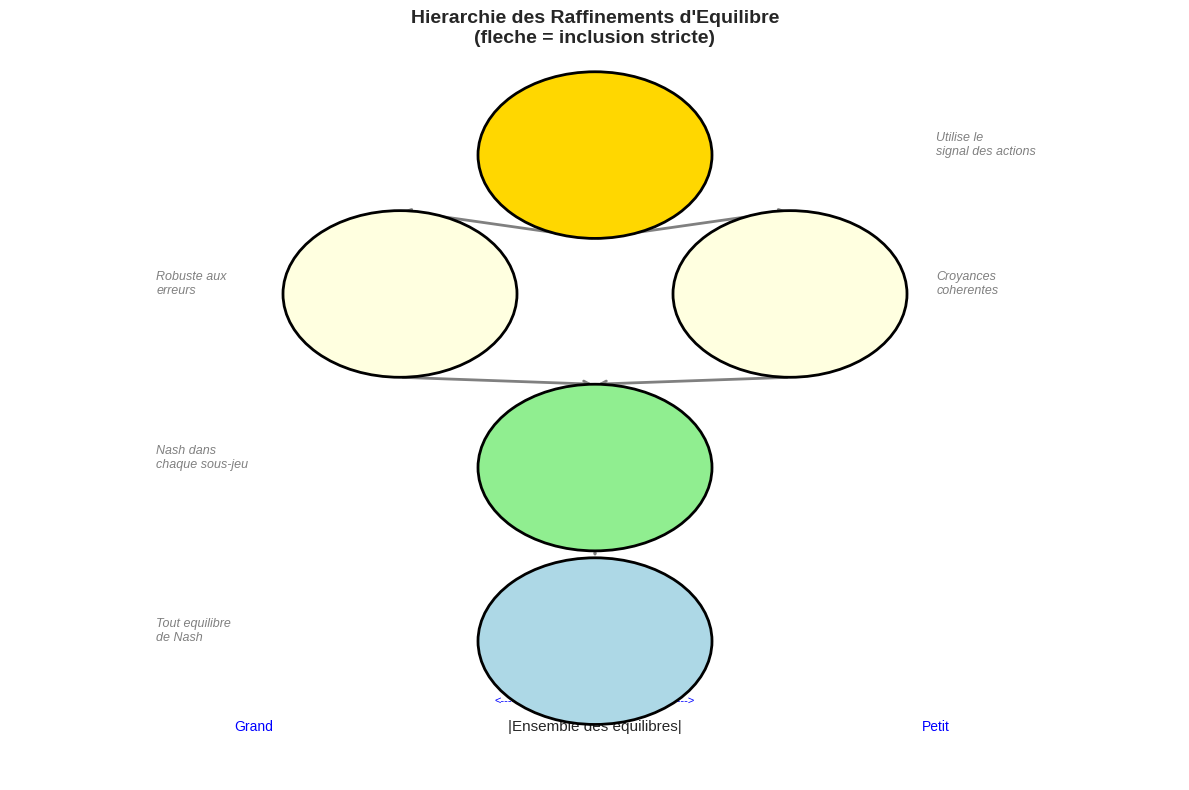

In [10]:
def visualize_refinement_hierarchy():
    """Visualisation de la hierarchie des raffinements d'equilibre."""
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Positions des concepts
    concepts = {
        'Nash': (0.5, 0.15, 'lightblue'),
        'SPE': (0.5, 0.40, 'lightgreen'),
        'Trembling-hand\nPerfect': (0.3, 0.65, 'lightyellow'),
        'Sequential\nEquilibrium': (0.7, 0.65, 'lightyellow'),
        'Forward\nInduction': (0.5, 0.85, 'gold'),
    }
    
    # Dessiner les noeuds
    for name, (x, y, color) in concepts.items():
        circle = plt.Circle((x, y), 0.12, color=color, ec='black', linewidth=2, zorder=5)
        ax.add_patch(circle)
        ax.annotate(name, (x, y), ha='center', va='center', fontsize=10, fontweight='bold')
    
    # Fleches (inclusion : concept du haut ⊂ concept du bas)
    arrows = [
        ('Forward\nInduction', 'Trembling-hand\nPerfect'),
        ('Forward\nInduction', 'Sequential\nEquilibrium'),
        ('Trembling-hand\nPerfect', 'SPE'),
        ('Sequential\nEquilibrium', 'SPE'),
        ('SPE', 'Nash'),
    ]
    
    for start, end in arrows:
        x1, y1, _ = concepts[start]
        x2, y2, _ = concepts[end]
        ax.annotate('', xy=(x2, y2 + 0.12), xytext=(x1, y1 - 0.12),
                   arrowprops=dict(arrowstyle='->', color='gray', lw=2))
    
    # Annotations explicatives
    annotations = [
        (0.05, 0.15, "Tout equilibre\nde Nash"),
        (0.05, 0.40, "Nash dans\nchaque sous-jeu"),
        (0.05, 0.65, "Robuste aux\nerreurs"),
        (0.85, 0.65, "Croyances\ncoherentes"),
        (0.85, 0.85, "Utilise le\nsignal des actions"),
    ]
    
    for x, y, text in annotations:
        ax.annotate(text, (x, y), fontsize=9, style='italic', color='gray')
    
    # Set cardinality indication
    ax.annotate("|Ensemble des equilibres|", (0.5, 0.02), ha='center', fontsize=11)
    ax.annotate("Grand", (0.15, 0.02), ha='center', fontsize=10, color='blue')
    ax.annotate("Petit", (0.85, 0.02), ha='center', fontsize=10, color='blue')
    ax.annotate("<" + "-"*50 + ">", (0.5, 0.06), ha='center', fontsize=8, color='blue')
    
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.05, 1.0)
    ax.axis('off')
    ax.set_title('Hierarchie des Raffinements d\'Equilibre\n(fleche = inclusion stricte)', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

visualize_refinement_hierarchy()

## 7. Exercices

### Exercice 1: Beer-Quiche Game

Jeu de signaling classique:
- Nature tire le type de J1: Tough (p=0.9) ou Weak (p=0.1)
- J1 choisit son petit-dejeuner: Beer ou Quiche
- J2 observe le petit-dej (pas le type) et decide: Fight ou Back off

Gains:
- J1 prefere son plat naturel: Tough->Beer, Weak->Quiche (+1)
- Si Fight contre Tough: (-1, -1)
- Si Fight contre Weak: (-1, +1)  
- Si Back off: (+2, 0)

Trouvez les equilibres et analysez par induction avant.

### Exercice 2: Negociation avec Options Exterieures

J1 et J2 negocient. J1 a une option exterieure (BATNA) de valeur x.
Analysez comment x affecte le résultat de la negociation.

### Exercice 3: Engagement Séquentiel

Dans le jeu de la chaîne de magasins, ajoutez la possibilite pour le monopole de s'engager au debut (cout k). 
Pour quelles valeurs de k est-ce profitable?

In [11]:
# Exercice 1: Beer-Quiche
def create_beer_quiche_game():
    """Cree le jeu Beer-Quiche."""
    # TODO etudiant : modeliser le jeu Beer-Quiche
    return None

# Exercice 2: BATNA
def analyze_batna(batna_values=[0, 1, 2, 3]):
    """Analyse l'effet du BATNA sur la negociation."""
    # TODO etudiant : implementer l'analyse BATNA
    return None

# Exercice 3: Engagement Sequentiel
# TODO etudiant : modeliser le jeu de la chaine de magasins avec engagement

print("Exercices a completer : Beer-Quiche, BATNA, Engagement sequentiel")

Exercices a completer : Beer-Quiche, BATNA, Engagement sequentiel


### Exercice 4 : Jeu d'entree avec signal de prix

Une firme en place (Incumbent) peut signaler sa force en fixant un prix bas avant qu'un entrant potentiel
(Entrant) ne decide d'entrer sur le marche.

- **Étape 1** : Modeliser le jeu sous forme extensive (signal -> entrée -> combat/accommodation)
- **Étape 2** : Identifier les equilibres de Forward Induction
- **Étape 3** : Comparer avec le résultat en information complete

*Indice* : Un prix bas peut etre un signal credible de force (le faible ne peut pas imiter).

In [12]:
# Exercice 4 : Jeu d'entree avec signal de prix
# TODO etudiant : modeliser le jeu d'entree avec signal
# Etape 1 : definir l'arbre (Incumbent: prix haut/bas, Entrant: entre/pas, Incumbent: combat/accommode)
# Etape 2 : forward induction - quel signal est credible ?
# Etape 3 : conclusion
def solve_entry_signaling() -> dict:
    return {"equilibrium_signal": None, "entrant_enters": None}  # TODO etudiant

print("Exercice a completer")

Exercice a completer


***

## Exercice 5 : Identification des SPE

**Objectifs** :

1. Distinguer Nash equilibria des SPE
2. Appliquer forward induction pour eliminer les equilibres non credibles
3. Analyser un jeu de signaux

**Contexte** : Un jeu d'entree sur un marche avec signal. L'entrant peut signaler fort ou faible. L'incumbent observe le signal et decide de combattre ou accommoder.

**Questions** :

1. Identifiez tous les equilibres de Nash
2. Lesquels sont des SPE ?
3. Comment forward induction selectionne-t-elle l'equilibre ?

In [13]:
# Exercice 5 : Forward Induction et SPE

# TODO etudiant : Modeliser le jeu d'entree avec signaux
# Joueur 1 (Entrant): signaler 'Fort' ou 'Faible', puis entrer ou non
# Joueur 2 (Incumbent): observer signal, combattre ou accommoder

# TODO etudiant : Trouver tous les equilibres de Nash
# def find_all_nash(payoffs):
#     ...

# TODO etudiant : Filtrer pour garder seulement les SPE
# def filter_spe(nash_equilibria):
#     ...

# TODO etudiant : Appliquer forward induction
# def forward_induction_selection(spe_list):
#     ...

print("Exercice a completer : identification des SPE et forward induction")

Exercice a completer : identification des SPE et forward induction


## 8. Resume

| Concept | Description |
|---------|-------------|
| **Sous-jeu** | Partie du jeu commencant a un noeud singleton |
| **SPE** | Nash dans chaque sous-jeu |
| **Menace credible** | Menace qu'il est optimal d'executer |
| **Induction avant** | Utiliser les actions observees pour inferer |
| **Trembling-hand** | Robuste aux petites erreurs |

### Points cles

- **SPE** elimine les menaces non credibles
- **L'engagement** peut rendre une menace credible
- **L'induction avant** interprète les actions observées sous des hypothèses de rationalité et de croyances ; les comparaisons calculées ici ne sélectionnent pas tous les SPE
- **Brûler de l'argent** peut signaler les intentions, conditionnellement au coût et aux continuations envisagées

### Prochaine étape

**Notebook 11 : Jeux Bayesiens** - Information incomplete, types, croyances, et equilibre bayesien de Nash.

**Lien avec la formalisation Lean**

L'equilibre de sous-jeux parfaits (SPE) raffine le concept d'equilibre de Nash en imposant la rationalite dans chaque sous-jeu. La structure `GameTree` et l'algorithme de minimax dans [`lean_game_defs/Combinatorial.lean`](lean_game_defs/Combinatorial.lean) formalisent l'induction a rebours pour les jeux a information parfaite -- le cas particulier zero-somme du backward induction que SPE generalise. Les concepts de forward induction et de perfection en main tremblante restent a formaliser.

## References

1. **Cho, I.-K. & Kreps, D. M. (1987).** *Signaling Games and Stable Equilibria.* Quarterly Journal of Economics 102(2): 179-221. -- the forward induction criterion and the Intuitive Criterion (selection d'equilibres par induction avant, application au carnet 10 sur les croyances hors-equilibre et la selection d'equilibres de Kreps-Wilson 1982).
2. **Kreps, D. M. & Wilson, R. (1982).** *Sequential Equilibria.* Econometrica 50(4): 863-894. -- equilibre sequentiel (beliefs + strategies), generalisation des SPE aux jeux a information imparfaite, fondation formelle du carnet 10 (forward induction + SPE).
3. **Selten, R. (1975).** *Reexamination of the Perfectness Concept for Equilibrium Points in Extensive Games.* International Journal of Game Theory 4(1): 25-55. -- introduction du concept d'equilibre parfait (perfectness/trembling hand), raffinement antecedent du SPE, fondation formelle de la perfection en mains tremblantes, complete par le backward induction du carnet 09 et l'extension au forward induction du carnet 10.
4. **Osborne, M. J. (2004).** *An Introduction to Game Theory* (international edition). Oxford University Press. -- manuel de reference Ch. 5 *Extensive Games with Perfect Information* (backward induction, sous-jeux parfaits) et Ch. 10 *Extensive Games with Imperfect Information* (formes extensives a information imparfaite).
5. **Mas-Colell, A., Whinston, M. D. & Green, J. R. (1995).** *Microeconomic Theory.* Oxford University Press. -- manuel avance dont le Ch. 9 *Dynamic Games* formalise la theorie du SPE en information parfaite et imparfaite, cadre analytique du carnet 10.
6. **Fudenberg, D. & Tirole, J. (1991).** *Game Theory.* MIT Press. -- manuel de reference dont le Ch. 3 *Extensive-Form Games* formalise backward induction et SPE, et dont le Ch. 11 *More Equilibrium Refinements: Stability, Forward Induction, and Iterated Weak Dominance* est le chapitre pertinent pour le carnet 10 (forward induction : comment les croyances initiales selectionnent l'equilibre parmi les sous-jeux parfaits).
7. **Bonanno, G. (2015).** *Game Theory* (open access textbook, 165 solved exercises). arXiv:1512.06808 [math.HO], **CC BY-NC-ND 4.0** (licence verifiee page de copyright du PDF, 2026-10-18 ; la metadonnee arXiv indique CC BY 4.0 mais la page de copyright du document prime). -- manuel pedagogique dont le §2.2 (backward induction), le §3.4 (subgame-perfect equilibrium) et le Ch. 11 *Sequential equilibrium* (Kreps-Wilson 1982) portent les concepts titulaires de ce carnet.


## Resume et perspectives

Ce notebook a constitue une étude approfondie des raffinements d'equilibre pour les jeux sous forme extensive, en distinguant leurs exigences et leur domaine de définition. L'equilibre parfait de sous-jeux (SPE) a elimine les menaces non credibles en exigeant un Nash dans chaque sous-jeu, comme l'a illustre le jeu d'entree ou la menace de combat n'est pas soutenable. L’exemple matriciel à deux joueurs illustre comment les tremblements écartent un équilibre faisant jouer des stratégies faiblement dominées. Pour les jeux finis à mémoire parfaite, la perfection extensive implique un équilibre séquentiel et un SPE ; la perfection en forme normale est une notion distincte. L'induction avant a introduit un raisonnement d'une nature différente : plutot que de partir de la fin du jeu, elle exploite les actions observees en debut de partie pour inferer les intentions des joueurs, dans l'exemple de la Chasse au Cerf, l'option extérieure est supérieure à tout gain obtenu en jouant Hare. Sous l'hypothèse d'une entrée visant un gain strictement supérieur à cette option, J2 peut inférer Stag ; les croyances nécessaires restent explicites.

Le jeu du "Burn Money" a synthetise ces concepts de maniere frappante : le coût du signal et les continuations possibles conditionnent ce que l'on peut inférer : avec le coût 0,5 de cet exemple, seul Opéra peut dépasser la continuation de référence (Foot, Foot), mais cette comparaison ne garantit pas une sélection sans hypothèse sur les croyances. Ces notions ne forment pas une hiérarchie universelle : le choix du raffinement dépend de la représentation du jeu et des hypothèses sur les erreurs et les croyances.

L'étape suivante introduit les jeux bayesiens et l'information incomplete, ou les joueurs ne connaissent pas les types de leurs adversaires : [GameTheory-11-BayesianGames-Python](GameTheory-11-BayesianGames-Python.ipynb).



### References academiques

- Selten, R. (1965). Spieltheoretische Behandlung eines Oligopolmodells mit Nachfragetragheit. Zeitschrift fur die gesamte Staatswissenschaft 121:301-324 et 667-689.
- Selten, R. (1975). Reexamination of the Perfectness Concept for Equilibrium Points in Extensive Games. International Journal of Game Theory 4(1):25-55.
- Kohlberg, E. & Mertens, J.-F. (1986). On the Strategic Stability of Equilibria. Econometrica 54(5):1003-1037.

